In [1]:
import pandas as pd
from pathlib import Path
from google.colab import drive

# 1. Collega il Drive (se è già collegato, Colab andrà semplicemente avanti)
drive.mount('/content/drive')

# 2. Definisci il percorso principale della tua cartella di progetto
project_path = Path("/content/drive/MyDrive/Codici definitivi_colab")

# 3. Costruisci il percorso esatto per il file CSV
percorso_csv = project_path / "df_features.csv"

# 4. Verifica di sicurezza ed estrazione dati
if percorso_csv.exists():
    print(f"\nFile trovato in: {percorso_csv}")

    # Caricamento del dataset
    df_features = pd.read_csv(percorso_csv)

    print(f"-> Dataset caricato con successo! Pazienti: {df_features.shape[0]}, Variabili: {df_features.shape[1]}")
else:
    print(f"\nERRORE CRITICO: Il file 'df_features.csv' non si trova dentro {project_path}")


Mounted at /content/drive

ERRORE CRITICO: Il file 'df_features.csv' non si trova dentro /content/drive/MyDrive/Codici definitivi_colab


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats as stats

In [3]:
df_features = pd.read_csv("/content/drive/MyDrive/Codici definitivi_colab/Analisi_Dataset/df_features.csv")

651


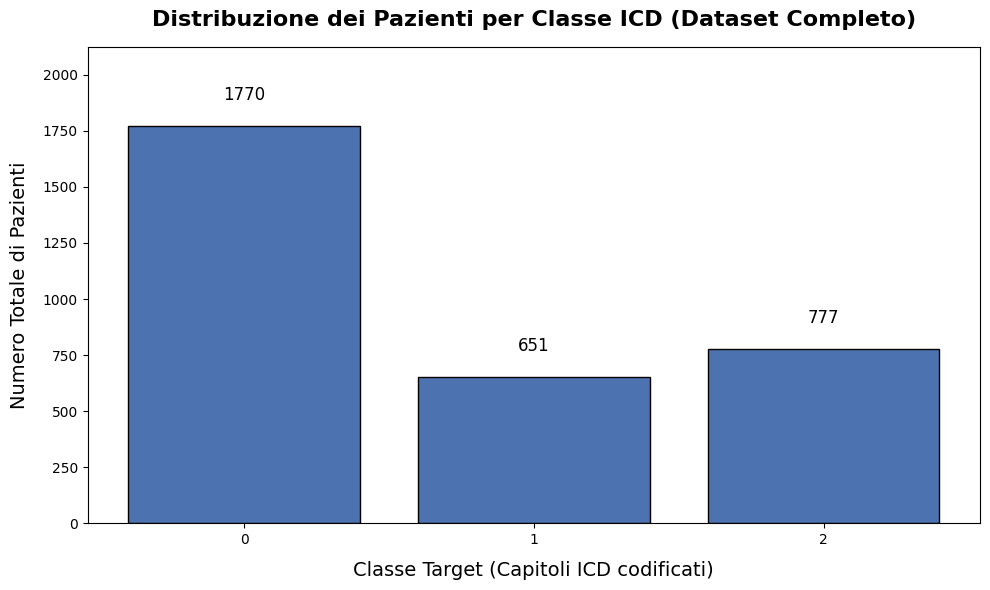

In [4]:
#Conteggio degli elementi per ogni classe
class_counts = df_features['target'].value_counts().sort_index()
min_class_count = min(class_counts)
print(min_class_count)

#Plotting

plt.figure(figsize=(10, 6))

bars = plt.bar(class_counts.index, class_counts.values, color='#4C72B0', edgecolor='black')
plt.ylim(0, max(class_counts.values) * 1.2)

plt.title("Distribuzione dei Pazienti per Classe ICD (Dataset Completo)", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Classe Target (Capitoli ICD codificati)", fontsize=14, labelpad=10)
plt.ylabel("Numero Totale di Pazienti", fontsize=14, labelpad=10)
plt.xticks(class_counts.index) # Mostriamo solo i numeri 0, 1, 2, 3, 4

#Numeri delle colonne
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2., height + 100,
             f'{int(height)}', ha='center', va='bottom', fontsize=12)

plt.tight_layout()
plt.show()

In [5]:
def analizza_nan_per_etichetta(df, titolo_step=""):
    """
    Analizza e visualizza la distribuzione dei NaN nel dataframe rispetto alla colonna 'target'.
    """
    # --- ANALISI DEI VALORI MANCANTI (NaN) PER ETICHETTA (TARGET) ---

    # Creiamo una lista vuota per salvare le statistiche
    stats_list = []

    # Iteriamo su ogni gruppo diviso per l'etichetta 'target'
    for label, group in df.groupby('target'):

        # 1. Quanti pazienti ci sono in totale per questa etichetta
        total_patients = len(group)

        # 2. Quanti pazienti hanno ALMENO UN NaN per questa etichetta (axis=1 controlla le righe)
        patients_with_nan = group.isna().any(axis=1).sum()

        # 3. Percentuale di pazienti con almeno un NaN su quelli con la stessa etichetta
        perc_patients_nan = (patients_with_nan / total_patients) * 100 if total_patients > 0 else 0

        # 4. Numero totale di celle dati per questa etichetta (righe * colonne)
        total_data_points = group.size

        # 5. Quanti NaN ci sono in totale per questa etichetta
        total_nans = group.isna().sum().sum()

        # 6. Percentuale di NaN su TUTTI i dati di questa etichetta
        perc_nans = (total_nans / total_data_points) * 100 if total_data_points > 0 else 0

        # Salviamo i risultati nel dizionario
        stats_list.append({
            'Target': label,
            'Pazienti Etichetta': total_patients,
            'Pazienti con >=1 NaN': patients_with_nan,
            '% Pazienti con NaN': perc_patients_nan,
            'NaN Totali': total_nans,
            '% NaN su Dati Etichetta': perc_nans
        })

    # Convertiamo in DataFrame per una visualizzazione ordinata
    stats_df = pd.DataFrame(stats_list)

    # Aggiungiamo il suffisso al titolo se presente
    titolo_testo = f" {titolo_step}" if titolo_step else ""
    print(f"--- RIASSUNTO NaN PER ETICHETTA{titolo_testo} ---")
    display(stats_df.round(2)) # Usiamo display() per una tabella formattata bene su Jupyter e arrotondiamo a 2 decimali

    # --- CREAZIONE DEL PLOT CON SOVRAPPOSIZIONE ---
    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.arange(len(stats_df['Target']))

    # Per ottenere l'effetto di sovrapposizione, disegniamo prima la barra dei pazienti totali (più alta)
    ax.bar(x, stats_df['Pazienti Etichetta'], label='Pazienti Etichetta', color='#a1c9f4', edgecolor='black', linewidth=1)

    # E poi disegniamo sopra la barra dei pazienti con NaN (più bassa) nella stessa posizione X
    ax.bar(x, stats_df['Pazienti con >=1 NaN'], label='Pazienti con almeno 1 NaN', color='#ffb482', edgecolor='black', linewidth=1)

    # Personalizziamo il grafico
    ax.set_ylabel('Numero di Pazienti', fontsize=12)
    ax.set_xlabel('Etichetta (Target)', fontsize=12)
    ax.set_title(f'Pazienti Totali vs Pazienti con NaN per Etichetta - {titolo_testo}', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(stats_df['Target'], fontsize=11)
    ax.legend(fontsize=11)

    # Aggiungiamo una griglia orizzontale leggera per facilitare la lettura
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

--- RIASSUNTO NaN PER ETICHETTA Analisi Iniziale ---


,Target,Pazienti Etichetta,Pazienti con >=1 NaN,% Pazienti con NaN,NaN Totali,% NaN su Dati Etichetta
0,0,1770,933,52.71,11206,4.46
1,1,651,254,39.02,1936,2.09
2,2,777,147,18.92,1036,0.94


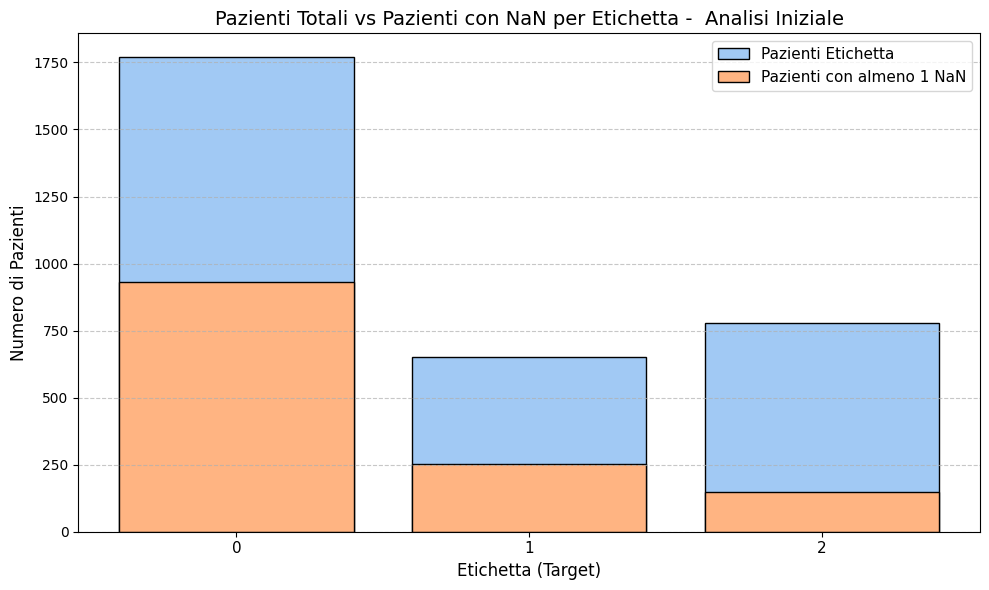

In [6]:
analizza_nan_per_etichetta(df_features,"Analisi Iniziale")

Analisi outliers con approccio manuale e statistico

Per i parametri fisiologici standard per tutte le classi sono applicate soglie che rientrano nei range possibili (es. temperatura)

In [7]:
print(list(df_features.columns))

['hadm_id', 'target', 'age', 'los_hours', 'mortality', 'admission_type_DIRECT EMER.', 'admission_type_DIRECT OBSERVATION', 'admission_type_ELECTIVE', 'admission_type_EU OBSERVATION', 'admission_type_EW EMER.', 'admission_type_OBSERVATION ADMIT', 'admission_type_SURGICAL SAME DAY ADMISSION', 'admission_type_URGENT', 'race_ASIAN', 'race_ASIAN - ASIAN INDIAN', 'race_ASIAN - CHINESE', 'race_ASIAN - KOREAN', 'race_ASIAN - SOUTH EAST ASIAN', 'race_BLACK/AFRICAN', 'race_BLACK/AFRICAN AMERICAN', 'race_BLACK/CAPE VERDEAN', 'race_BLACK/CARIBBEAN ISLAND', 'race_HISPANIC/LATINO - CENTRAL AMERICAN', 'race_HISPANIC/LATINO - COLUMBIAN', 'race_HISPANIC/LATINO - CUBAN', 'race_HISPANIC/LATINO - DOMINICAN', 'race_HISPANIC/LATINO - GUATEMALAN', 'race_HISPANIC/LATINO - HONDURAN', 'race_HISPANIC/LATINO - MEXICAN', 'race_HISPANIC/LATINO - PUERTO RICAN', 'race_HISPANIC/LATINO - SALVADORAN', 'race_NATIVE HAWAIIAN OR OTHER PACIFIC ISLANDER', 'race_OTHER', 'race_PATIENT DECLINED TO ANSWER', 'race_PORTUGUESE', 'r

Modifica del dataset per eliminare gli outliers

In [8]:
#Creazione di un file di features modificato

df_features_mod = df_features

--- RIASSUNTO NaN PER ETICHETTA Analisi quantità di NaN ---


,Target,Pazienti Etichetta,Pazienti con >=1 NaN,% Pazienti con NaN,NaN Totali,% NaN su Dati Etichetta
0,0,1770,933,52.71,11206,4.46
1,1,651,254,39.02,1936,2.09
2,2,777,147,18.92,1036,0.94


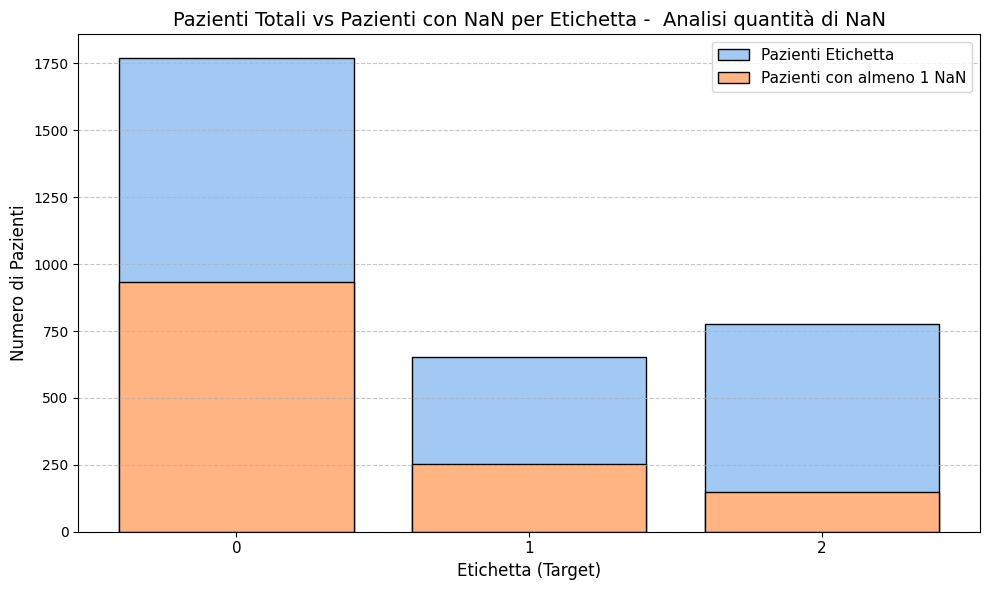

In [9]:
analizza_nan_per_etichetta(df_features_mod,"Analisi quantità di NaN")

In [10]:
import sys
import pandas as pd
from pathlib import Path

# 1. SETUP PERCORSI IN BASE ALLA STRUTTURA DELLE CARTELLE
project_path = Path("/content/drive/MyDrive/Codici definitivi_colab")

# Definiamo dove lavorare e dove salvare (direttamente dentro Analisi_Dataset)
analisi_dataset_path = project_path / "Analisi_Dataset"

# Indichiamo a Python la sottocartella esatta dove trovare il modulo
modulo_path = project_path / "nan_and_imputation_function"
if str(modulo_path) not in sys.path:
    sys.path.insert(0, str(modulo_path))

# Importiamo le tue funzioni ufficiali
from nan_and_imputation_handling import fit_nan_handler, transform_nan

print("\n" + "="*60)
print(" IMPUTAZIONE NaN TRAMITE MODULO PERSONALIZZATO")
print("="*60)

# 2. PREPARAZIONE DEL DATASET (usiamo df_features_mod già in memoria)
y = df_features_mod['target']
X_raw = df_features_mod.drop(columns=['target'])

hadm_id_col = None
if 'hadm_id' in X_raw.columns:
    hadm_id_col = X_raw['hadm_id']
    X_raw = X_raw.drop(columns=['hadm_id'])

# 3. FIT & TRANSFORM DEI DATI
print("Fase 1: Apprendimento regole di imputazione...")
fitted_handler = fit_nan_handler(
    X_train=X_raw,
    impute=True,
    pool="all",
    strategy="median", # Usiamo la mediana per rapidità esplorativa
    add_missing_flag=True
)

print("Fase 2: Applicazione imputazione e creazione flag...")
# Salviamo il report direttamente in Analisi_Dataset
percorso_report = str(analisi_dataset_path / "report_imputazione_esplorativa.csv")
X_imputed = transform_nan(X_raw, fitted_handler, output_report_path=percorso_report)

# 4. RICOMPOSIZIONE E SALVATAGGIO
# Riuniamo ID, feature imputate/flag e target
df_da_salvare = X_imputed.copy()
if hadm_id_col is not None:
    df_da_salvare.insert(0, 'hadm_id', hadm_id_col.values)
df_da_salvare['target'] = y.values

# Salviamo il csv direttamente in Analisi_Dataset
percorso_salvataggio = analisi_dataset_path / "df_imputed_pipeline.csv"
df_da_salvare.to_csv(percorso_salvataggio, index=False)

print(f"\n-> Operazione completata!")
print(f"-> Dataset imputato salvato in: {percorso_salvataggio}")


 IMPUTAZIONE NaN TRAMITE MODULO PERSONALIZZATO
Fase 1: Apprendimento regole di imputazione...
Fase 2: Applicazione imputazione e creazione flag...

[REPORT NaN] Totale valori mancanti (NaN) trovati: 14178
Dettaglio NaN per colonna (prime colonne con NaN):
temperature           92
heartrate             89
resprate              90
o2sat                 92
sbp                   91
dbp                   92
pain                 108
acuity                82
Hemoglobin_mean      153
Hemoglobin_median    153
dtype: int64
  Report dettagliato dei NaN salvato in: /content/drive/MyDrive/Codici definitivi_colab/Analisi_Dataset/report_imputazione_esplorativa.csv

-> Operazione completata!
-> Dataset imputato salvato in: /content/drive/MyDrive/Codici definitivi_colab/Analisi_Dataset/df_imputed_pipeline.csv


In [11]:
import pandas as pd
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

print("1. Standardizzazione delle feature in corso...")
scaler = StandardScaler()
# Usiamo direttamente X_imputed generato dalla cella precedente
X_scaled = scaler.fit_transform(X_imputed)

# =============================================================================
# ELABORAZIONE PCA 3D
# =============================================================================
print("\n2. Calcolo PCA 3D in corso...")
pca = PCA(n_components=3, random_state=42)
componenti_pca = pca.fit_transform(X_scaled)

var_spiegata = pca.explained_variance_ratio_ * 100
var_totale = var_spiegata.sum()
print(f"-> Varianza trattenuta dalla PCA: {var_spiegata[0]:.1f}%, {var_spiegata[1]:.1f}%, {var_spiegata[2]:.1f}% (Totale: {var_totale:.1f}%)")

df_pca = pd.DataFrame(data=componenti_pca, columns=['PC1', 'PC2', 'PC3'])
df_pca['Classe Target'] = y.astype(str)

fig_pca = px.scatter_3d(
    df_pca, x='PC1', y='PC2', z='PC3', color='Classe Target',
    title=f'PCA 3D - Dataset Imputato (Varianza Totale Mostrata: {var_totale:.1f}%)',
    color_discrete_sequence=px.colors.qualitative.Set1,
    opacity=0.75
)
fig_pca.update_traces(marker=dict(size=4, line=dict(width=0.5, color='DarkSlateGrey')))
fig_pca.show()

# =============================================================================
# ELABORAZIONE t-SNE 3D
# =============================================================================
print("\n3. Calcolo t-SNE 3D in corso (questo passaggio richiede più tempo)...")
tsne = TSNE(n_components=3, perplexity=30, random_state=42, init='pca', learning_rate='auto')
componenti_tsne = tsne.fit_transform(X_scaled)

df_tsne = pd.DataFrame(data=componenti_tsne, columns=['Dim_1', 'Dim_2', 'Dim_3'])
df_tsne['Classe Target'] = y.astype(str)

fig_tsne = px.scatter_3d(
    df_tsne, x='Dim_1', y='Dim_2', z='Dim_3', color='Classe Target',
    title='t-SNE 3D - Mappa Topologica Cluster Locali',
    color_discrete_sequence=px.colors.qualitative.Set1,
    opacity=0.8
)
fig_tsne.update_traces(marker=dict(size=4, line=dict(width=0.5, color='DarkSlateGrey')))
fig_tsne.show()

1. Standardizzazione delle feature in corso...

2. Calcolo PCA 3D in corso...
-> Varianza trattenuta dalla PCA: 10.1%, 5.2%, 4.2% (Totale: 19.5%)



3. Calcolo t-SNE 3D in corso (questo passaggio richiede più tempo)...
